In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
warnings.filterwarnings('ignore')
import datetime as dt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer, MaxAbsScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, HuberRegressor, ElasticNet
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, HuberRegressor, ElasticNet
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.metrics import  r2_score,mean_squared_error,mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [2]:
df = pd.read_csv("../data/H2_cleaned.csv")
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,HasCompany
0,0,6,2015,July,27,1,0,2,1.0,0.0,...,No Deposit,6.0,0,Transient,100.0,0,0,Check-Out,2015-07-03,0
1,1,88,2015,July,27,1,0,4,2.0,0.0,...,No Deposit,9.0,0,Transient,76.5,0,1,Canceled,2015-07-01,0
2,1,65,2015,July,27,1,0,4,1.0,0.0,...,No Deposit,9.0,0,Transient,68.0,0,1,Canceled,2015-04-30,0
3,1,92,2015,July,27,1,2,4,2.0,0.0,...,No Deposit,9.0,0,Transient,76.5,0,2,Canceled,2015-06-23,0
4,1,100,2015,July,27,2,0,2,2.0,0.0,...,No Deposit,9.0,0,Transient,76.5,0,1,Canceled,2015-04-02,0


In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 53093 entries, 0 to 53092
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   53093 non-null  int64  
 1   LeadTime                     53093 non-null  int64  
 2   ArrivalDateYear              53093 non-null  int64  
 3   ArrivalDateMonth             53093 non-null  str    
 4   ArrivalDateWeekNumber        53093 non-null  int64  
 5   ArrivalDateDayOfMonth        53093 non-null  int64  
 6   StaysInWeekendNights         53093 non-null  int64  
 7   StaysInWeekNights            53093 non-null  int64  
 8   Adults                       53093 non-null  float64
 9   Children                     53093 non-null  float64
 10  Babies                       53093 non-null  float64
 11  Meal                         53093 non-null  str    
 12  Country                      53093 non-null  str    
 13  MarketSegment              

In [4]:
print((df.isna().sum()).sort_values(ascending=False))

Agent                          5491
LeadTime                          0
IsCanceled                        0
ArrivalDateMonth                  0
ArrivalDateWeekNumber             0
ArrivalDateDayOfMonth             0
ArrivalDateYear                   0
StaysInWeekNights                 0
Adults                            0
Children                          0
Babies                            0
Meal                              0
Country                           0
MarketSegment                     0
StaysInWeekendNights              0
DistributionChannel               0
IsRepeatedGuest                   0
PreviousBookingsNotCanceled       0
PreviousCancellations             0
ReservedRoomType                  0
AssignedRoomType                  0
BookingChanges                    0
DepositType                       0
DaysInWaitingList                 0
CustomerType                      0
ADR                               0
RequiredCarParkingSpaces          0
TotalOfSpecialRequests      

In [5]:
df.nunique()

IsCanceled                        2
LeadTime                        453
ArrivalDateYear                   3
ArrivalDateMonth                 12
ArrivalDateWeekNumber            53
ArrivalDateDayOfMonth            31
StaysInWeekendNights             12
StaysInWeekNights                26
Adults                            5
Children                          4
Babies                            5
Meal                              4
Country                          14
MarketSegment                     7
DistributionChannel               4
IsRepeatedGuest                   2
PreviousCancellations            10
PreviousBookingsNotCanceled      73
ReservedRoomType                  7
AssignedRoomType                  8
BookingChanges                   18
DepositType                       3
Agent                           223
DaysInWaitingList               114
CustomerType                      4
ADR                            5389
RequiredCarParkingSpaces          4
TotalOfSpecialRequests      

In [6]:
obj_cols = df.select_dtypes(include='object').columns
for col in obj_cols:
    print(f"Column: {col}")
    print(df[col].unique())
    print("\n")

Column: ArrivalDateMonth
<StringArray>
[     'July',    'August', 'September',   'October',  'November',  'December',
   'January',  'February',     'March',     'April',       'May',      'June']
Length: 12, dtype: str


Column: Meal
<StringArray>
['HB       ', 'BB       ', 'SC       ', 'FB       ']
Length: 4, dtype: str


Column: Country
<StringArray>
[  'PRT',   'ITA',   'ESP',   'DEU',   'FRA',   'NLD',   'GBR', 'Other',
   'BRA',   'AUT',   'BEL',   'CHE',   'IRL',   'USA']
Length: 14, dtype: str


Column: MarketSegment
<StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',      'Aviation']
Length: 7, dtype: str


Column: DistributionChannel
<StringArray>
['TA/TO', 'Direct', 'Corporate', 'GDS']
Length: 4, dtype: str


Column: ReservedRoomType
<StringArray>
['A               ', 'B               ', 'D               ',
 'F               ', 'E               ', 'G               ',
 'C               ']
Length: 7, dtype: str


In [7]:
obj_cols = df.select_dtypes(include='object').columns
for col in obj_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print("\n")

Column: ArrivalDateMonth
ArrivalDateMonth
August       6569
July         5724
May          5376
April        5061
June         4966
March        4830
September    4227
October      4187
February     3586
December     2997
November     2867
January      2703
Name: count, dtype: int64


Column: Meal
Meal
BB           40988
SC            9312
HB            2782
FB              11
Name: count, dtype: int64


Column: Country
Country
PRT      13119
Other     8053
FRA       7399
GBR       4520
DEU       4465
ESP       3777
ITA       2641
BEL       1690
BRA       1587
NLD       1430
USA       1413
CHE       1151
IRL       1067
AUT        781
Name: count, dtype: int64


Column: MarketSegment
MarketSegment
Online TA        34909
Offline TA/TO     7185
Direct            5534
Groups            2536
Corporate         2200
Complementary      503
Aviation           226
Name: count, dtype: int64


Column: DistributionChannel
DistributionChannel
TA/TO        44324
Direct        6052
Corporate     2536


In [8]:
num_cols = df.select_dtypes(include='number').columns
for col in num_cols:
    print(f"Column: {col}")
    print(df[col].unique())
    print("\n")

Column: IsCanceled
[0 1]


Column: LeadTime
[  6  88  65  92 100  79   3  63  62  43   4  97  80  60 106  68  18  71
  85  75  89  83  72 111  86  73  55  69  76  61  77  54  90 117 105  51
  24  84 115  67  87 109  96 114  66  59 122 123  94 120   0 125  82 107
 103  12 118 108 119  20  22  99 112  93 132 110   2  15  98 124  16  19
  81   5  27  25 126  74   1  64 138 102  78 130 135   7  28  34 141  33
 101  13  11  36 128  30 145 142  39 121 147 140 104  41 134 150   8 133
  10  40 131   9 137 127  46  47  14 151  17  44 113  53  50 162 148 149
  21  23  37  49  26  32  52 173  45 164  42  58  48 168  31  38 175 170
  29  35 167 166  56 152 155 116  95  57 179  70 192 169 193 199 204 200
  91 198 158 210 156 174 184 180 195 216 233 212 139 242 208 146 144 159
 197 129 160 154 393 251 157 161 136 182 267 274 268 190 281 188 275 270
 265 288 143 295 443 194 437 253 207 302 259 178 289 298 286 309 196 273
 276 297 191 451 217 323 316 189 322 211 163 172 153 205 202 330 177 220
 247 21

In [9]:
season_map = {
    'December': 'Winter', 'January': 'Winter', 'February': 'Winter',
    'March': 'Spring',    'April': 'Spring',   'May': 'Spring',
    'June': 'Summer',     'July': 'Summer',    'August': 'Summer',
    'September': 'Fall',  'October': 'Fall',   'November': 'Fall'
}
df['Season'] = df['ArrivalDateMonth'].str.strip().map(season_map)

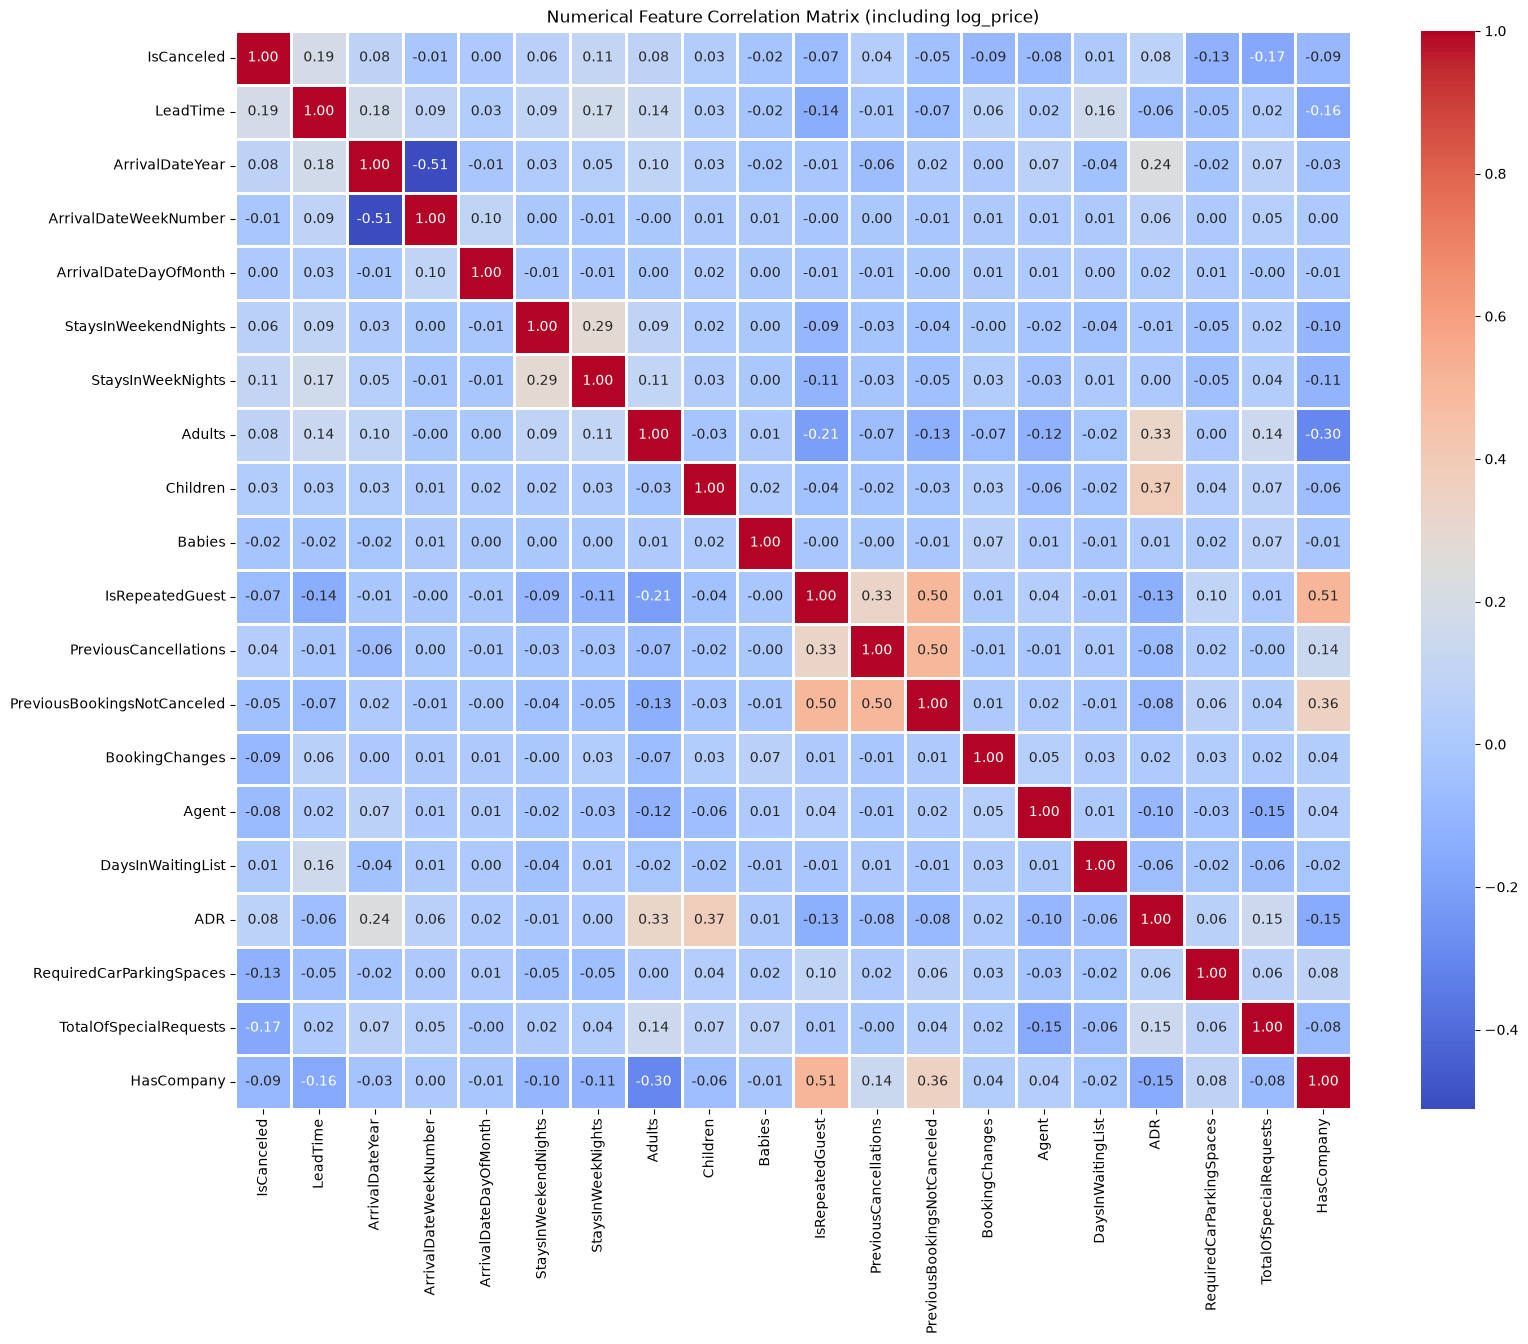

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True),annot=True, fmt=".2f", cmap="coolwarm",linewidths=0.8)
plt.title("Numerical Feature Correlation Matrix (including log_price)")
plt.show()

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53093 entries, 0 to 53092
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   53093 non-null  int64  
 1   LeadTime                     53093 non-null  int64  
 2   ArrivalDateYear              53093 non-null  int64  
 3   ArrivalDateMonth             53093 non-null  str    
 4   ArrivalDateWeekNumber        53093 non-null  int64  
 5   ArrivalDateDayOfMonth        53093 non-null  int64  
 6   StaysInWeekendNights         53093 non-null  int64  
 7   StaysInWeekNights            53093 non-null  int64  
 8   Adults                       53093 non-null  float64
 9   Children                     53093 non-null  float64
 10  Babies                       53093 non-null  float64
 11  Meal                         53093 non-null  str    
 12  Country                      53093 non-null  str    
 13  MarketSegment              

In [12]:
print((df.isna().sum()).sort_values(ascending=False))

Agent                          5491
IsCanceled                        0
ArrivalDateYear                   0
LeadTime                          0
ArrivalDateWeekNumber             0
ArrivalDateDayOfMonth             0
StaysInWeekendNights              0
ArrivalDateMonth                  0
Adults                            0
Children                          0
Babies                            0
Meal                              0
Country                           0
MarketSegment                     0
DistributionChannel               0
StaysInWeekNights                 0
IsRepeatedGuest                   0
PreviousCancellations             0
ReservedRoomType                  0
PreviousBookingsNotCanceled       0
AssignedRoomType                  0
BookingChanges                    0
DepositType                       0
DaysInWaitingList                 0
CustomerType                      0
ADR                               0
RequiredCarParkingSpaces          0
TotalOfSpecialRequests      

In [13]:
df_clean = df.copy()

In [14]:
numeric_df = df_clean.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
target_correlations = corr_matrix['ADR']
cols_to_drop = []
for col, corr_value in target_correlations.items():
    if col != 'ADR' and abs(corr_value) < 0.1:
        cols_to_drop.append(col)
        print(f"Marked for dropping: '{col}' (Correlation: {corr_value:.4f})")
df_filtered = df_clean.drop(columns=cols_to_drop)
print(f"\nDropped {len(cols_to_drop)} columns due to low correlation.")

Marked for dropping: 'IsCanceled' (Correlation: 0.0777)
Marked for dropping: 'LeadTime' (Correlation: -0.0583)
Marked for dropping: 'ArrivalDateWeekNumber' (Correlation: 0.0649)
Marked for dropping: 'ArrivalDateDayOfMonth' (Correlation: 0.0192)
Marked for dropping: 'StaysInWeekendNights' (Correlation: -0.0136)
Marked for dropping: 'StaysInWeekNights' (Correlation: 0.0028)
Marked for dropping: 'Babies' (Correlation: 0.0134)
Marked for dropping: 'PreviousCancellations' (Correlation: -0.0765)
Marked for dropping: 'PreviousBookingsNotCanceled' (Correlation: -0.0841)
Marked for dropping: 'BookingChanges' (Correlation: 0.0164)
Marked for dropping: 'Agent' (Correlation: -0.0968)
Marked for dropping: 'DaysInWaitingList' (Correlation: -0.0605)
Marked for dropping: 'RequiredCarParkingSpaces' (Correlation: 0.0576)

Dropped 13 columns due to low correlation.


In [15]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 53093 entries, 0 to 53092
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   53093 non-null  int64  
 1   LeadTime                     53093 non-null  int64  
 2   ArrivalDateYear              53093 non-null  int64  
 3   ArrivalDateMonth             53093 non-null  str    
 4   ArrivalDateWeekNumber        53093 non-null  int64  
 5   ArrivalDateDayOfMonth        53093 non-null  int64  
 6   StaysInWeekendNights         53093 non-null  int64  
 7   StaysInWeekNights            53093 non-null  int64  
 8   Adults                       53093 non-null  float64
 9   Children                     53093 non-null  float64
 10  Babies                       53093 non-null  float64
 11  Meal                         53093 non-null  str    
 12  Country                      53093 non-null  str    
 13  MarketSegment              

In [16]:
from sklearn.model_selection import train_test_split

print((df_filtered.isna().sum()).sort_values(ascending=False))

ArrivalDateYear           0
ArrivalDateMonth          0
Adults                    0
Children                  0
Meal                      0
Country                   0
MarketSegment             0
DistributionChannel       0
IsRepeatedGuest           0
ReservedRoomType          0
AssignedRoomType          0
DepositType               0
CustomerType              0
ADR                       0
TotalOfSpecialRequests    0
ReservationStatus         0
ReservationStatusDate     0
HasCompany                0
Season                    0
dtype: int64


In [17]:

X = df_filtered.drop(columns=['ADR'])
y = df_filtered['ADR']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
NUM = [  "Adults", "Children", "DaysInWaitingList", "ADR"]
CAT = ["ArrivalDateMonth", "Meal", "Country", "MarketSegment", "DistributionChannel",
       "ReservedRoomType", "DepositType", "CustomerType"]
BINARY = ["IsRepeatedGuest", "HasCompany"]

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, OrdinalEncoder

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category','datetime64[ns]']).columns.tolist()
categorical_cols.remove('ArrivalDateMonth')
categorical_cols.remove('MarketSegment')
categorical_cols.remove('DistributionChannel')
label_cols = ['ArrivalDateMonth', 'MarketSegment', 'DistributionChannel']
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)
le= LabelEncoder()
for col in label_cols:
    X[col] = le.fit_transform(X[col])
    


In [20]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 53093 entries, 0 to 53092
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ArrivalDateYear         53093 non-null  int64  
 1   ArrivalDateMonth        53093 non-null  int64  
 2   Adults                  53093 non-null  float64
 3   Children                53093 non-null  float64
 4   Meal                    53093 non-null  str    
 5   Country                 53093 non-null  str    
 6   MarketSegment           53093 non-null  int64  
 7   DistributionChannel     53093 non-null  int64  
 8   IsRepeatedGuest         53093 non-null  int64  
 9   ReservedRoomType        53093 non-null  str    
 10  AssignedRoomType        53093 non-null  str    
 11  DepositType             53093 non-null  str    
 12  CustomerType            53093 non-null  str    
 13  TotalOfSpecialRequests  53093 non-null  int64  
 14  ReservationStatus       53093 non-null  str    
 

In [21]:
from sklearn.model_selection import KFold, cross_validate
kf = KFold(n_splits=20, shuffle=True, random_state=42)

In [22]:
models = {
    'Ridge': Ridge(),
    #'Random Forest': RandomForestRegressor(),
    'XGBoost': XGBRegressor(),
    #'Gradient Boosting': GradientBoostingRegressor(),
    'Linear Regression': LinearRegression(),
    #'SVR': SVR(),
    'CatBoost': CatBoostRegressor(verbose=0),
    #'7oda Amr': HuberRegressor(epsilon=1.001, alpha=0.0001, max_iter=500)
}

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

print("--- K-FOLD CROSS VALIDATION RESULTS ---")

for name, model in models.items():

    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
        ])
    scores = cross_validate(
        pipe,
        X,
        y,
        cv=kf,
        scoring=scoring,
        n_jobs=-1
    )

    mae = -scores['test_MAE'].mean()
    rmse = -scores['test_RMSE'].mean()
    r2 = scores['test_R2'].mean()

    print(
        f"{name:15} | "
        f"RMSE: {rmse:.4f} | "
        f"MAE: {mae:.4f} | "
        f"R²: {r2:.4f}"
    )

--- K-FOLD CROSS VALIDATION RESULTS ---
Ridge           | RMSE: 24.6618 | MAE: 18.5623 | R²: 0.6043
XGBoost         | RMSE: 23.2615 | MAE: 17.3085 | R²: 0.6479
Linear Regression | RMSE: 24.6503 | MAE: 18.5585 | R²: 0.6046
CatBoost        | RMSE: 22.8280 | MAE: 17.0102 | R²: 0.6609


In [23]:
models = {
    'Ridge': Ridge(),
    #'Random Forest': RandomForestRegressor(),
    'XGBoost': XGBRegressor(),
    #'Gradient Boosting': GradientBoostingRegressor(),
    'Linear Regression': LinearRegression(),
    #'SVR': SVR(),
    'CatBoost': CatBoostRegressor(verbose=0)
}

print("---RESULTS ---")
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"{name:15} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | R²: {r2:.4f}")

---RESULTS ---
Ridge           | RMSE: 24.6284 | MAE: 18.5887 | R²: 0.6118
XGBoost         | RMSE: 23.2366 | MAE: 17.3675 | R²: 0.6544
Linear Regression | RMSE: 24.6261 | MAE: 18.5841 | R²: 0.6119
CatBoost        | RMSE: 22.8418 | MAE: 17.1388 | R²: 0.6661
